# Plotting metric correlations with ComplexHeatmap

In [1]:
library(ComplexHeatmap)
library(Matrix)
library(data.table)
library(grid)
library(circlize)
library(RColorBrewer)
library(viridis)
library(svglite)

Loading required package: grid

ComplexHeatmap version 2.22.0
Bioconductor page: http://bioconductor.org/packages/ComplexHeatmap/
Github page: https://github.com/jokergoo/ComplexHeatmap
Documentation: http://jokergoo.github.io/ComplexHeatmap-reference

If you use it in published research, please cite either one:
- Gu, Z. Complex Heatmap Visualization. iMeta 2022.
- Gu, Z. Complex heatmaps reveal patterns and correlations in multidimensional 
    genomic data. Bioinformatics 2016.


The new InteractiveComplexHeatmap package can directly export static 
complex heatmaps into an interactive Shiny app with zero effort. Have a try!

This message can be suppressed by:
  suppressPackageStartupMessages(library(ComplexHeatmap))


circlize version 0.4.16
CRAN page: https://cran.r-project.org/package=circlize
Github page: https://github.com/jokergoo/circlize
Documentation: https://jokergoo.github.io/circlize_book/book/

If you use it in published research, please cite:
Gu, Z. circlize implements a

## Transcriptomics bioconservation metrics

In [24]:
df <- read.csv('../results/spreadsheets/bioconservation_corr.csv', row.names = 1)
mat <- as.matrix(df)

rownames(mat) <- toupper(rownames(mat))
colnames(mat) <- toupper(colnames(mat))
mat <- mat[rownames(mat) != "GCD", ]
mat <- mat[, colnames(mat) != "GCD"]

In [25]:
piyg_colors <- brewer.pal(11, "PiYG")

col_fun = colorRamp2(
  seq(-1, 1, length.out = 11), 
  piyg_colors
)

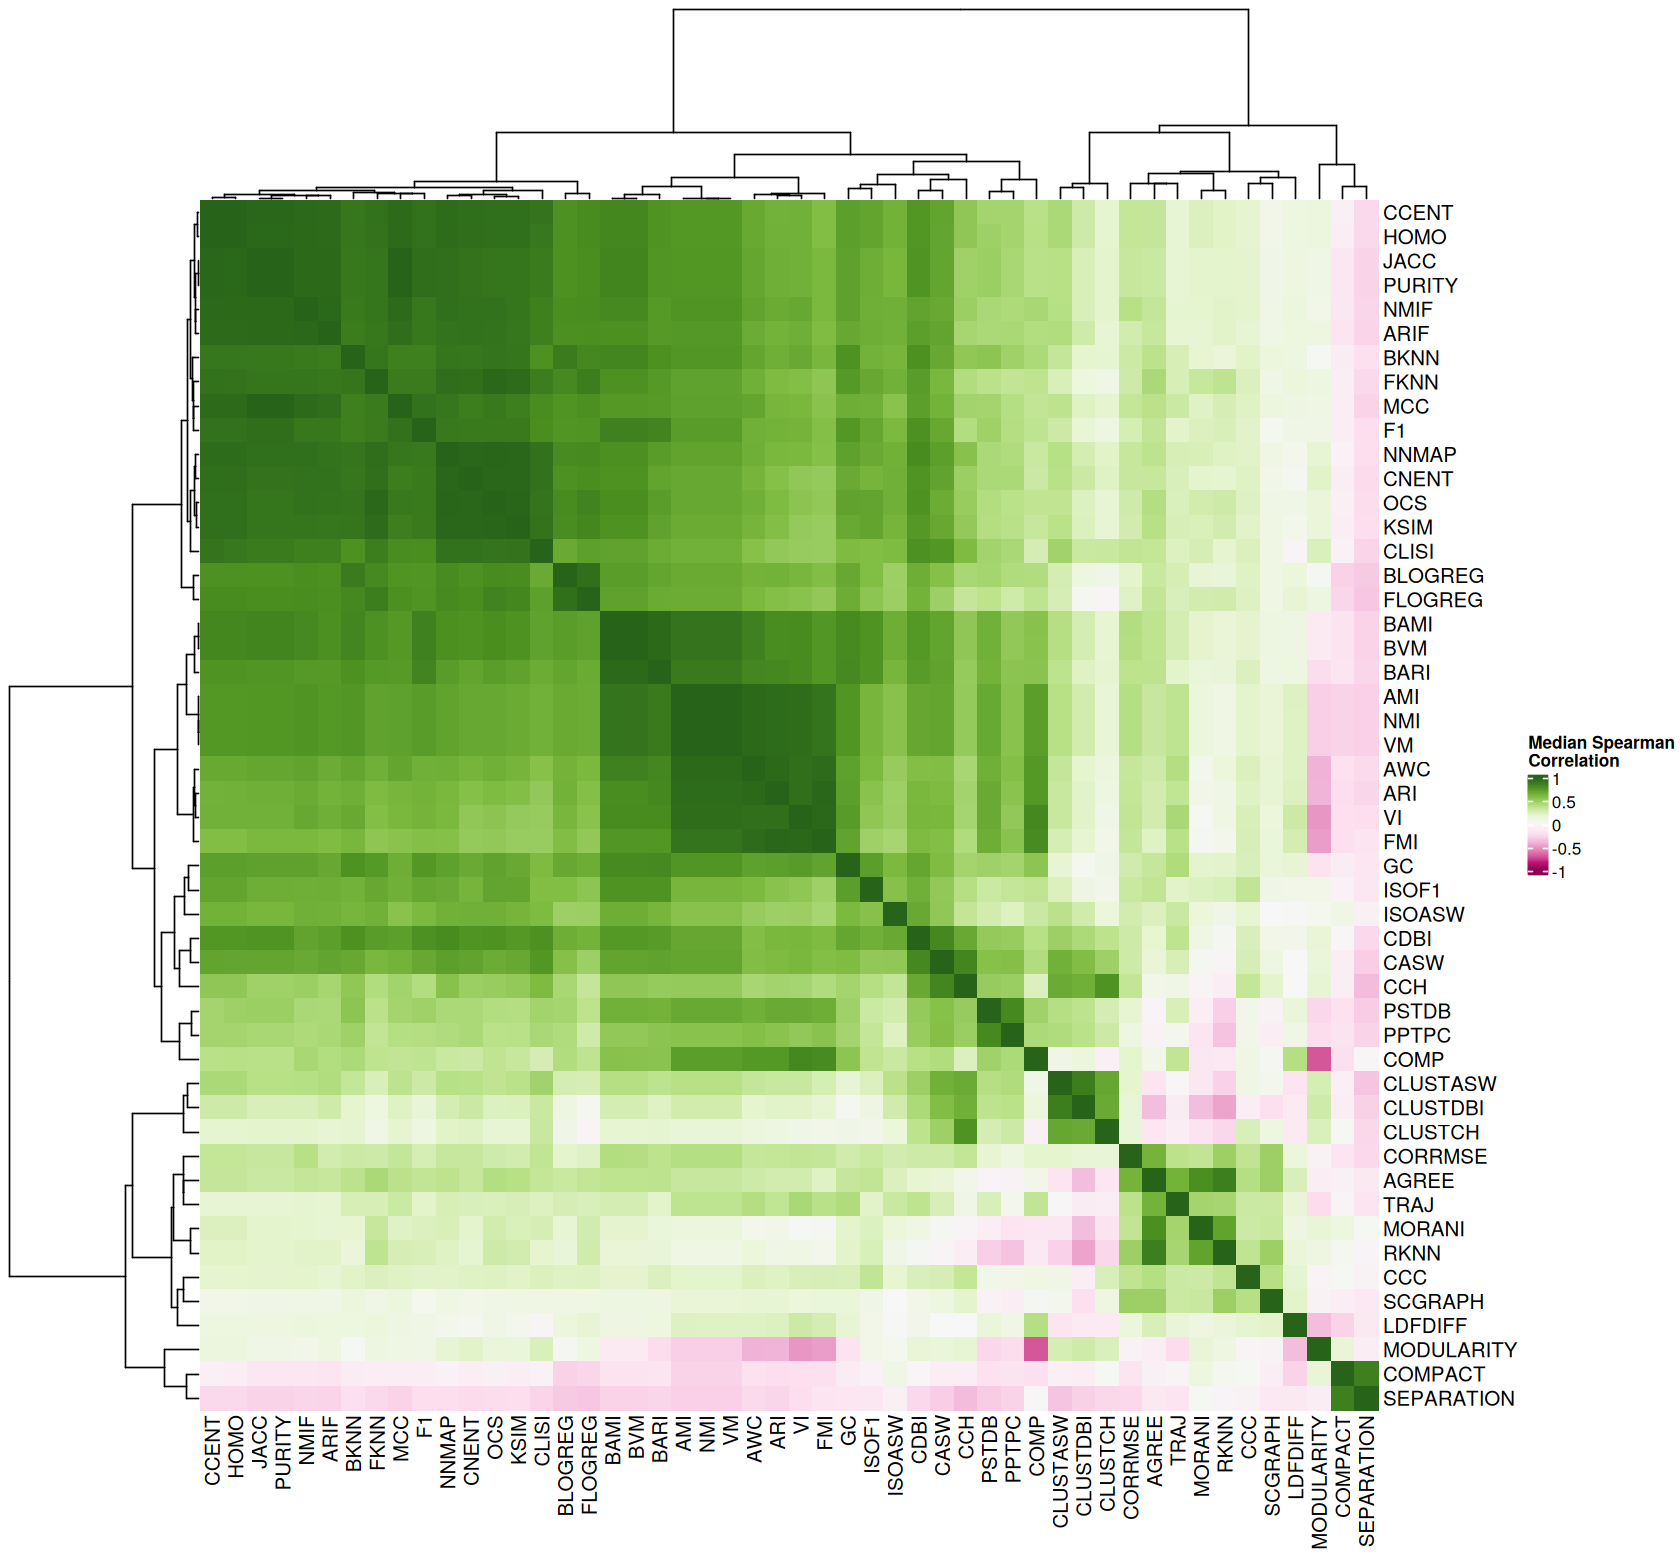

In [26]:
options(repr.plot.width=14, repr.plot.height=13)
Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(4, "cm"),
    row_dend_width = unit(4, "cm"),
)

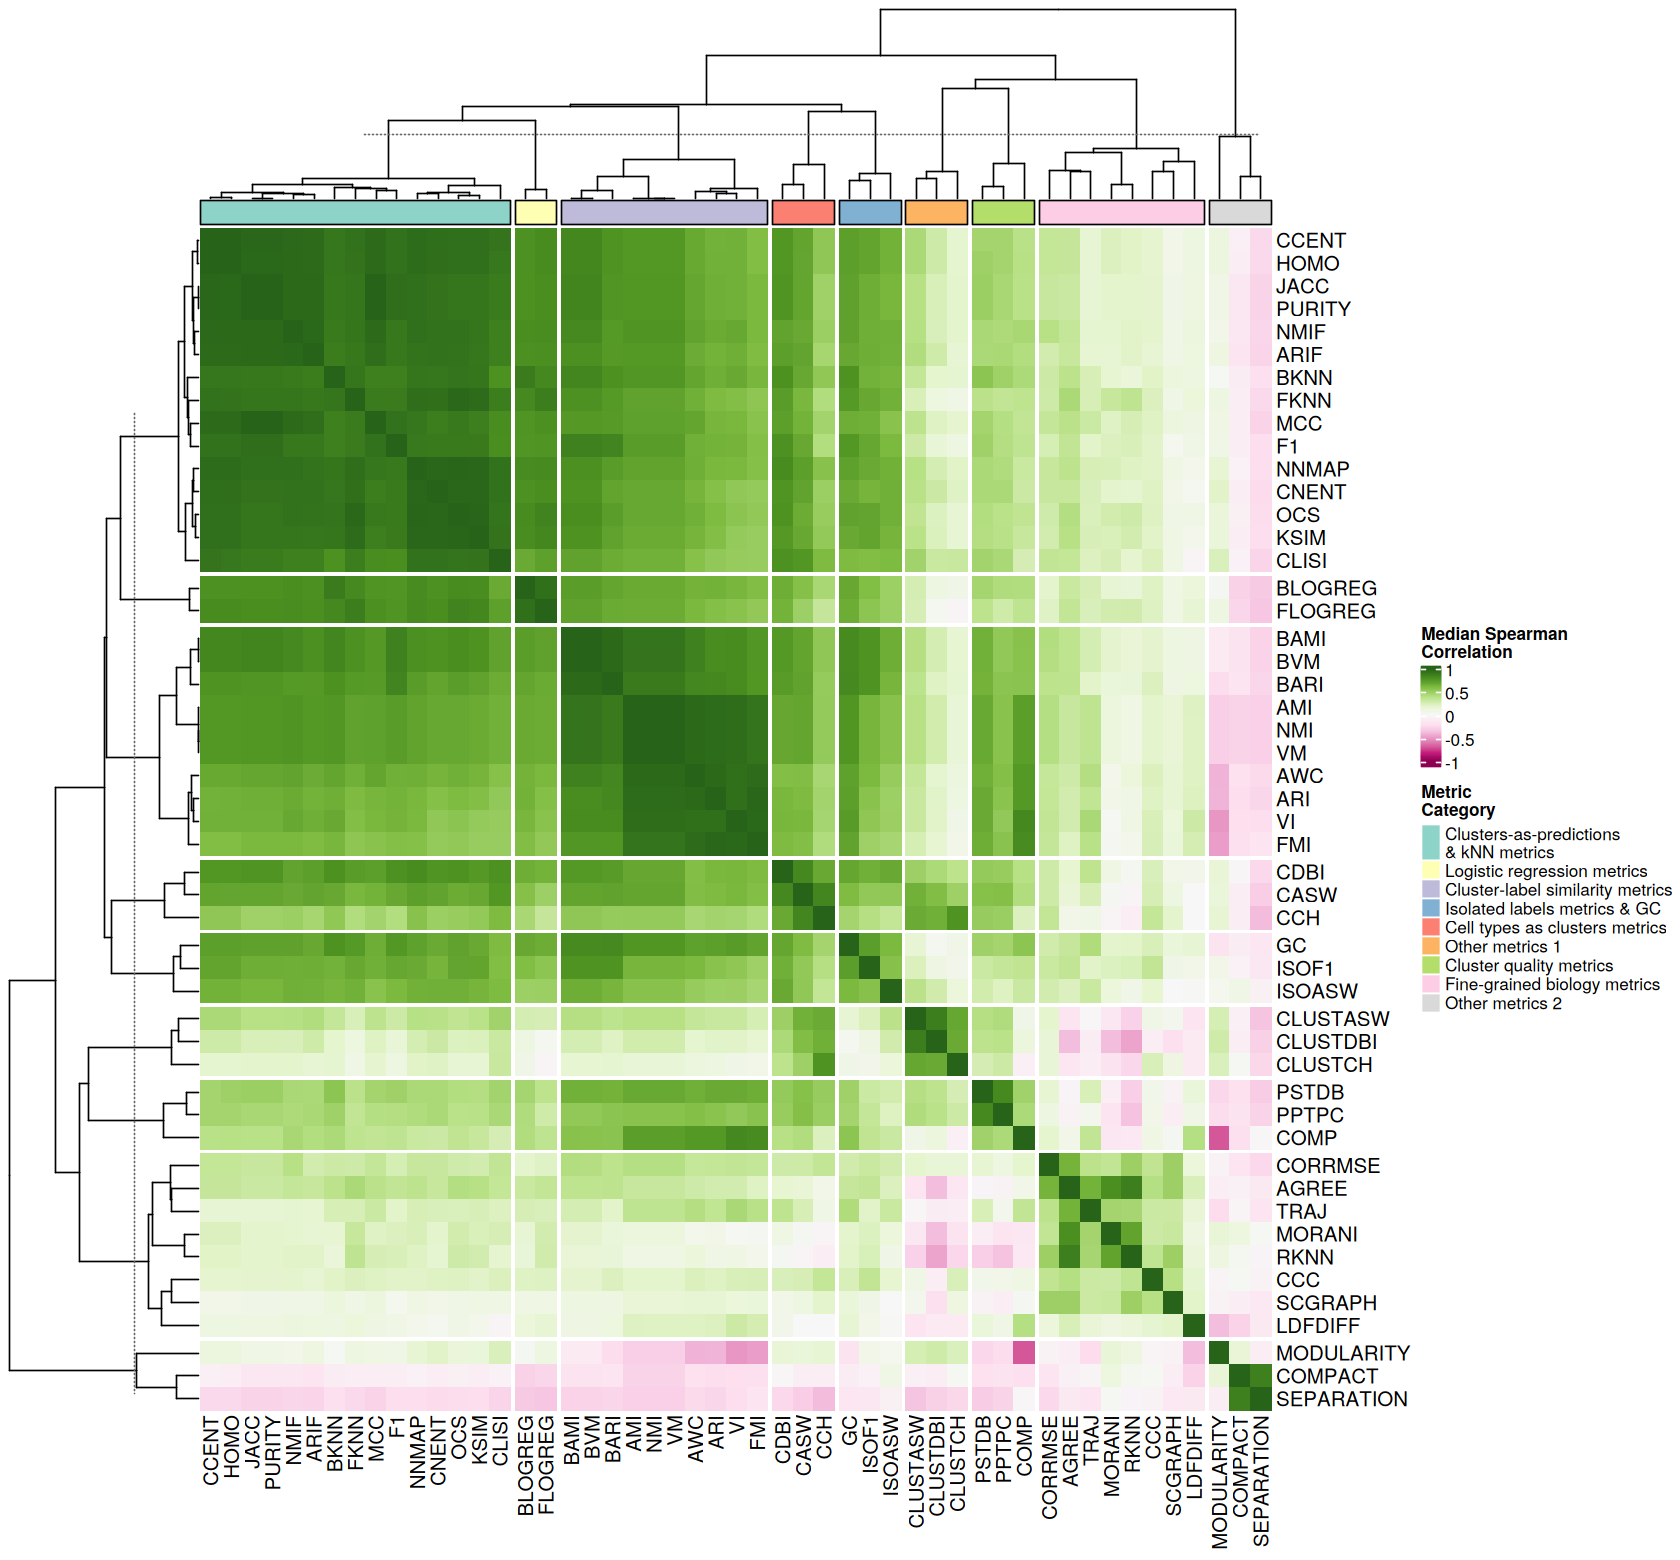

In [27]:
options(repr.plot.width=14, repr.plot.height=13)

# png("../publication_figures/bioconservation_corr.png", width = 15, height = 14, units = "in", res = 300)
my_block_cols = brewer.pal(11, "Set3")
grouping_map <- c(
    'FMI' = 2, 'AWC' = 2, 'ARI' = 2, 'VI' = 2, 'NMI' = 2, 'AMI' = 2, 'VM' = 2, 
    'BARI' = 2, 'BAMI' = 2, 'BVM' = 2, 
    'ISOASW' = 3, 'GC' = 3, 'ISOF1' = 3, 
    'CASW' = 4, 'CDBI' = 4, 'CCH' = 4, 'BLOGREG' = 1, 'FLOGREG' = 1, 'CLISI' = 0, 
    'FKNN' = 0, 'KSIM' = 0, 'OCS' = 0, 'NNMAP' = 0, 'CNENT' = 0, 'BKNN' = 0, 
    'F1' = 0, 'MCC' = 0, 'JACC' =0, 'PURITY' = 0, 'CCENT' = 0, 'HOMO' = 0, 'ARIF' = 0, 'NMIF' = 0, 
    'CLUSTCH' = 6, 'CLUSTASW' = 6, 'CLUSTDBI' = 6, 'COMP' = 5, 'PPTPC' = 5, 'PSTDB' = 5, 
    'LDFDIFF' = 7, 'AGREE' = 7, 'MORANI' = 7, 'RKNN' = 7, 'CCC' = 7, 'SCGRAPH' = 7, 'CORRMSE' = 7, 'TRAJ' = 7, 
    'MODULARITY' = 8, 'COMPACT' = 8, 'SEPARATION' = 8
)
column_groups <- grouping_map[colnames(mat)]
column_groups_factor <- factor(column_groups, levels = 0:9)

lgd = Legend(
    title = "Metric\nCategory",
    at = c(0, 1, 2,3,4,5,6,7,8),
    labels = c(
        'Clusters-as-predictions\n& kNN metrics',
        'Logistic regression metrics',
        'Cluster-label similarity metrics',
        'Isolated labels metrics & GC',
        'Cell types as clusters metrics',
        'Other metrics 1',
        'Cluster quality metrics',
        'Fine-grained biology metrics',
        'Other metrics 2'
    ),
    legend_gp = gpar(fill = my_block_cols[c(1, 2, 3, 5, 4, 6, 7, 8, 9)])
)


ht = Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(4, "cm"),
    row_dend_width = unit(4, "cm"),
    column_split = column_groups_factor, 
    row_split = column_groups_factor,
    
    column_title = NULL,
    row_title = NULL,
        
    top_annotation = HeatmapAnnotation(
        group = anno_block(
            gp = gpar(fill = my_block_cols),
            labels_gp = gpar(col = "white", fontsize = 10)
        )
    ),
)
ht_drawn <- draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd),
    merge_legend = TRUE,
    heatmap_legend_side = "right",
    annotation_legend_side = "right"
)

row_ord_bio <- row_order(ht_drawn)
col_ord_bio <- column_order(ht_drawn)
# dev.off()

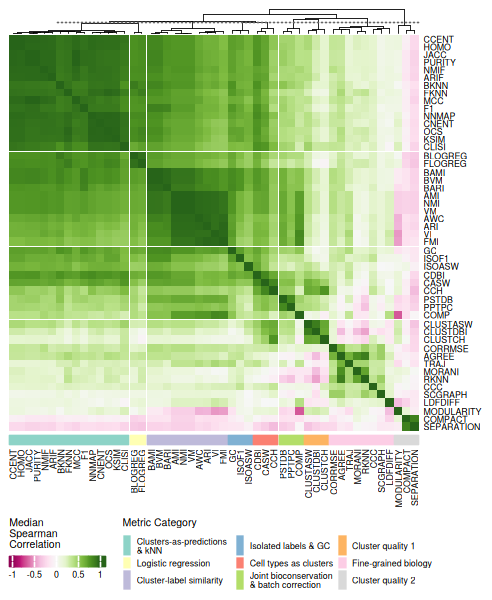

In [28]:
options(repr.plot.width=4.1, repr.plot.height=5)
# FINAL FIGURE

# svglite("../publication_figures/bioconservation_corr.svg", width = 4.1, height = 5)
grouping_map <- c(
    'FMI' = '2', 'AWC' = '2', 'ARI' = '2', 'VI' = '2', 'NMI' = '2', 'AMI' = '2', 'VM' = '2', 
    'BARI' = '2', 'BAMI' = '2', 'BVM' = '2', 
    'ISOASW' = '4', 'GC' = '4', 'ISOF1' = '4', 
    'CASW' = '3', 'CDBI' = '3', 'CCH' = '3', 'BLOGREG' = '1', 'FLOGREG' = '1', 'CLISI' = '0', 
    'FKNN' = '0', 'KSIM' = '0', 'OCS' = '0', 'NNMAP' = '0', 'CNENT' = '0', 'CNENTROPYW' = '0', 'BKNN' = '0', 
    'F1' = '0', 'MCC' = '0', 'JACC' = '0', 'PURITY' = '0', 'CCENT' = '0', 'HOMO' = '0', 'ARIF' = '0', 'NMIF' = '0', 
    'CLUSTCH' = '5', 'CLUSTASW' = '5', 'CLUSTDBI' = '5', 'COMP' = '6', 'PPTPC' = '6', 'PSTDB' = '6', 
    'LDFDIFF' = '7', 'AGREE' = '7', 'MORANI' = '7', 'RKNN' = '7', 'CCC' = '7', 'SCGRAPH' = '7', 'CORRMSE' = '7', 'TRAJ' = '7', 
    'MODULARITY' = '8', 'COMPACT' = '8', 'SEPARATION' = '8'
)

col_groups <- unname(grouping_map[colnames(mat)])
ann_colors = brewer.pal(9, "Set3")
names(ann_colors) = as.character(0:8)

lgd = Legend(
    title = "Metric Category",
    type = "grid",
    labels = c(
        'Clusters-as-predictions\n& kNN',
        'Logistic regression',
        'Cluster-label similarity',
        'Isolated labels & GC',
        'Cell types as clusters',
        'Joint bioconservation\n& batch correction',
        'Cluster quality 1',
        'Fine-grained biology',
        'Cluster quality 2'
    ),
    legend_gp = gpar(fill = c(
        my_block_cols[1],  # 0
        my_block_cols[2],  # 1
        my_block_cols[3],  # 2
        my_block_cols[5],  # 3 -> label for 4
        my_block_cols[4],  # 4 -> label for 3
        my_block_cols[7],  # 5
        my_block_cols[6],  # 6
        my_block_cols[8],  # 7
        my_block_cols[9]   # 8
    )),
    title_gp = gpar(fontsize = 6),
    labels_gp = gpar(fontsize = 5),
    grid_height = unit(2, "mm"),
    grid_width = unit(2, "mm"),
    ncol=3
)


ht = Heatmap(
    mat, name = "Median\nSpearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(.2, "in"),
    row_split = col_groups,
    column_split = col_groups,
    column_title = NULL,
    row_title = NULL,
    show_row_dend = FALSE,
    row_gap = unit(.3, "mm"),
    column_gap = unit(.3, "mm"),
    column_dend_gp = gpar(lwd = 0.5),
        
    bottom_annotation = HeatmapAnnotation(
        group = anno_simple(
            col_groups, height = unit(2, "mm"),
            col = ann_colors, border=F
        ),
        show_legend = FALSE,
        show_annotation_name = FALSE,
        border = F
        
    ),
    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize =6),
        legend_height = unit(3, "mm"),
        legend_width = unit(2, "cm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm"),
        direction = "horizontal"
        
    ),
    row_names_gp = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5)
)
draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd),
    merge_legend = TRUE,
    heatmap_legend_side = "bottom",
    annotation_legend_side = "bottom"
)
# dev.off()

In [16]:
df <- read.csv('../results/spreadsheets/bioconservation_corr_std.csv', row.names = 1)
mat <- as.matrix(df)

rownames(mat) <- toupper(rownames(mat))
colnames(mat) <- toupper(colnames(mat))

In [17]:
row_ord_flat <- unlist(row_ord_bio)
col_ord_flat <- unlist(col_ord_bio)

In [18]:
col_fun = colorRamp2(c(0, max(mat)/2, max(mat)), brewer.pal(3, "Blues"))

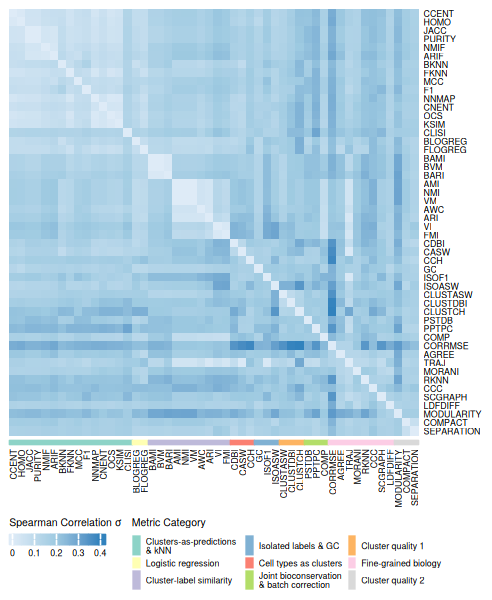

In [21]:
options(repr.plot.width=4.1, repr.plot.height=5)
# svglite("../publication_figures/bioconservation_std.svg", width = 4.1, height = 5)

ht <- Heatmap(
    mat, name = "Spearman Correlation σ",
    col = col_fun,

    # Fix the order to match the first heatmap
    row_order    = row_ord_flat,
    column_order = col_ord_flat,

    # No clustering needed — order is pre-specified
    cluster_rows    = FALSE,
    cluster_columns = FALSE,

    column_dend_height = unit(4, "cm"),
    row_dend_width     = unit(4, "cm"),

    # Row/column label font
    row_names_gp    = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5),

    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize =6),
        legend_height = unit(3, "mm"),
        legend_width = unit(2, "cm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm"),
        direction = "horizontal"
    ),
    bottom_annotation = HeatmapAnnotation(
        group = anno_simple(
            col_groups, height = unit(1, "mm"),
            col = ann_colors, border=F
        ),
        show_legend = FALSE,
        show_annotation_name = FALSE,
        border = F
        
    ),
)
ht_drawn <- draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd),
    merge_legend = TRUE,
    heatmap_legend_side = "bottom",
    annotation_legend_side = "bottom"
)
# dev.off()

## Transcriptomics batch correction metrics

In [3]:
df <- read.csv('../results/spreadsheets/batch_corr.csv', row.names = 1)
mat <- as.matrix(df)

rownames(mat) <- toupper(rownames(mat))
colnames(mat) <- toupper(colnames(mat))

mat <- mat[rownames(mat) != "GCD", ]
mat <- mat[, colnames(mat) != "GCD"]

In [4]:
piyg_colors <- brewer.pal(11, "PiYG")

col_fun = colorRamp2(
  seq(-1, 1, length.out = 11), 
  piyg_colors
)

In [43]:
options(repr.plot.width=11, repr.plot.height=10)

my_block_cols = brewer.pal(9, "Set1")

ht = Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(2, "cm"),
    row_dend_width = unit(2, "cm"),
    
    column_title = NULL,
    row_title = NULL,
    show_row_dend = FALSE,

    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 20),
        title_gp = gpar(fontsize = 20)
    ),
    row_names_gp = gpar(fontsize = 20),
    column_names_gp = gpar(fontsize = 20)
)
draw(
    ht,
    ht_gap = unit(7, "mm")
)

In [ ]:
options(repr.plot.width=2.7, repr.plot.height=3.5)
# png("../publication_figures/cpcr_cprobe_batch_corr.png", width = 2.7, height = 3.5, units = "in", res = 300)

my_block_cols = brewer.pal(9, "Set1")
highlight_rows <- c("CPROBELR", "CPROBERF", "CPROBE", 'CPCR')
highlight_cols <- c("CPROBELR", "CPROBERF", "CPROBE", "CPCR")

row_faces <- ifelse(rownames(mat) %in% highlight_rows, "bold", "plain")
col_faces <- ifelse(colnames(mat) %in% highlight_cols, "bold", "plain")

ht = Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(.2, "in"),
    row_dend_width = unit(2, "cm"),
    row_gap = unit(.3, "mm"),
    column_gap = unit(.3, "mm"),
    column_dend_gp = gpar(lwd = 0.5),
    
    column_title = NULL,
    row_title = NULL,
    show_row_dend = FALSE,

    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize =6),
        legend_height = unit(3, "mm"),
        legend_width = unit(1.7, "cm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm"),
        direction = "horizontal"
    ),
    row_names_gp = gpar(fontsize = 5, fontface = row_faces),
    column_names_gp = gpar(fontsize = 5, fontface = col_faces)
)
ht_drawn <- draw(
    ht,
    ht_gap = unit(7, "mm"),
    merge_legend = TRUE,
    heatmap_legend_side = "bottom",
    annotation_legend_side = "bottom"
)
# dev.off()

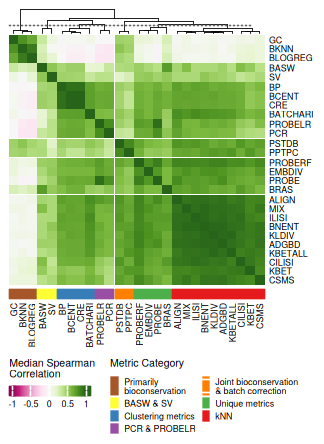

In [8]:
options(repr.plot.width=2.7, repr.plot.height=3.7)

# svglite("../publication_figures/batch_corr.svg", width = 2.7, height = 3.7)
my_block_cols = brewer.pal(9, "Set1")
grouping_map <- c(
    'MIX' = 0, "ALIGN" = 0, "ILISI" = 0, "BNENT" = 0, "KLDIV" = 0,
    "ADGBD" = 0, "KBETALL" = 0, "CILISI" = 0, "CSMS" = 0, "KBET" = 0,
    "BRAS" = 1, "EMBDIV" = 1, "PROBE" = 1, "PROBERF" = 1,
    "BATCHARI" = 2, "BP" = 2, "BCENT" = 2, "CRE" = 2,
    "PROBELR" = 3, "PCR" = 3,
    "PSTDB" = 4, "PPTPC" = 4, "BASW" = 5, "SV" = 5, "GC" = 6, "BKNN" = 6, "BLOGREG" = 6
)

col_groups <- unname(grouping_map[colnames(mat)])
ann_colors = brewer.pal(9, "Set1")
names(ann_colors) = as.character(0:8)
ann_colors["2"] <- '#377EB8'
ann_colors["1"] <- '#4DAF4A'

lgd = Legend(
    title = "Metric Category",
    type = "grid",
    labels = c(
        'Primarily\nbioconservation',
        'BASW & SV',
        'Clustering metrics',
        'PCR & PROBELR',
        'Joint bioconservation\n& batch correction',
        'Unique metrics',
        'kNN'
    ),
    legend_gp = gpar(fill = c(
        my_block_cols[7],
        my_block_cols[6],
        my_block_cols[2],
        my_block_cols[4],
        my_block_cols[5],
        my_block_cols[3],
        my_block_cols[1]
    )),
    title_gp = gpar(fontsize = 6),
    labels_gp = gpar(fontsize = 5),
    grid_height = unit(2, "mm"),
    grid_width = unit(2, "mm"),
    ncol=2
)

ht = Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(.2, "in"),
    row_split = col_groups,
    column_split = col_groups,
    row_gap = unit(.3, "mm"),
    column_gap = unit(.3, "mm"),
    column_dend_gp = gpar(lwd = 0.5),

    column_title = NULL,
    row_title = NULL,
    show_row_dend = FALSE,
        
    bottom_annotation = HeatmapAnnotation(
        group = anno_simple(
            col_groups, height = unit(2, "mm"),
            col = ann_colors, border=F),
        show_legend = FALSE,
        show_annotation_name = FALSE,
        border = F
    ),
    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize =6),
        legend_height = unit(3, "mm"),
        legend_width = unit(1.7, "cm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm"),
        direction = "horizontal"
    ),
    row_names_gp = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5)
)
ht_drawn <- draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd),
    merge_legend = TRUE,
    heatmap_legend_side = "bottom",
    annotation_legend_side = "bottom"
)

row_ord_batch <- row_order(ht_drawn)
col_ord_batch <- column_order(ht_drawn)
# dev.off()

In [9]:
df <- read.csv('../results/spreadsheets/batch_corr_std.csv', row.names = 1)
mat <- as.matrix(df)

rownames(mat) <- toupper(rownames(mat))
colnames(mat) <- toupper(colnames(mat))

In [10]:
row_ord_flat <- unlist(row_ord_batch)
col_ord_flat <- unlist(col_ord_batch)

In [11]:
col_fun = colorRamp2(c(0, max(mat)/2, max(mat)), brewer.pal(3, "Blues"))

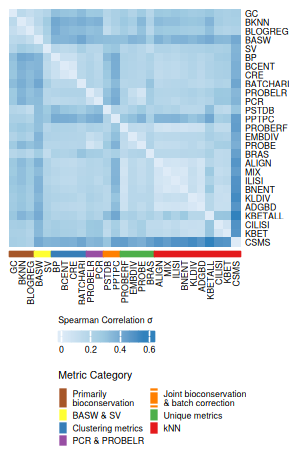

In [14]:
options(repr.plot.width=2.5, repr.plot.height=3.8)
# svglite("../publication_figures/batch_std.svg", width = 2.5, height = 3.8)

ht <- Heatmap(
    mat, name = "Spearman Correlation σ",
    col = col_fun,

    row_order    = row_ord_flat,
    column_order = col_ord_flat,

    cluster_rows    = FALSE,
    cluster_columns = FALSE,

    column_dend_height = unit(4, "cm"),
    row_dend_width     = unit(4, "cm"),

    # Row/column label font
    row_names_gp    = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5),

    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize = 5),
        legend_height = unit(3, "mm"),
        legend_width = unit(2, "cm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm"),
        direction = "horizontal"
    ),
    bottom_annotation = HeatmapAnnotation(
        group = anno_simple(
            col_groups, height = unit(1, "mm"),
            col = ann_colors, border=F),
        show_legend = FALSE,
        show_annotation_name = FALSE,
        border = F
    ),
)
ht_drawn <- draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd),
    merge_legend = TRUE,
    heatmap_legend_side = "bottom",
    annotation_legend_side = "bottom"
)
# dev.off()

# OVERALL

In [33]:
df <- read.csv('../results/spreadsheets/overall_corr.csv', row.names = 1)
mat <- as.matrix(df)

# Capitalize all row names
rownames(mat) <- toupper(rownames(mat))

# Capitalize all column names
colnames(mat) <- toupper(colnames(mat))

In [34]:
piyg_colors <- brewer.pal(11, "PiYG")

col_fun = colorRamp2(
  seq(-1, 1, length.out = 11), 
  piyg_colors
)

In [35]:
# Define the sets with all names uppercased
BIO <- toupper(c('agree', 'ami', 'ari', 'arif', 'awc', 'bami', 'bari', 'bvm', 'casw', 
                 'ccc', 'cch', 'ccent', 'clustch', 'clisi', 'clustasw', 'clustdbi', 
                 'cnent', 'comp', 'compact', 'corrmse', 'cdbi', 'f1', 
                 'fknn', 'flogreg', 'fmi', 'homo', 'isoasw', 'isof1', 'jacc', 'ksim', 
                 'ldfdiff', 'mcc', 'modularity', 'morani', 'nmi', 'nmif', 'nnmap', 
                 'ocs', 'purity', 'rknn', 'scgraph', 'separation', 'traj', 'vi', 'vm'))

BATCH <- toupper(c('adgbd', 'align', 'basw', 'batchari', 'bcent', 'bknn', 'blogreg', 
                   'bnent', 'bp', 'bras', 'cre', 'cilisi', 'csms', 'gc', 
                   'ilisi', 'kbet', 'kbetall', 'kldiv', 'embdiv', 'mix','pcr', 'pptpc', 
                   'probe', 'proberf', 'probelr', 'pstdb', 'sv'))

BOTH <- toupper(c('pptpc', 'pstdb', 'blogreg', 'bknn', 'gc'))

# Combine into a unique set of all metric names
ALL_METRICS <- sort(unique(c(BIO, BATCH)))

# Create the mapping vector
# Initialize with NA
type_map <- setNames(rep(NA, length(ALL_METRICS)), ALL_METRICS)

# Assign groups (Uppercase labels: "BIO", "BATCH", "BOTH")
type_map[names(type_map) %in% BIO]   <- "Bioconservation metrics"
type_map[names(type_map) %in% BATCH] <- "Batch correction metrics"
type_map[names(type_map) %in% BOTH]  <- "Joint metrics"

# Finalize as a clean named character vector
type_map <- setNames(as.character(type_map), ALL_METRICS)

In [38]:
options(repr.plot.width=7, repr.plot.height=6.9)

# svglite("../publication_figures/overall_corr.svg", width = 6.5, height = 6.2)
my_block_cols = brewer.pal(9, "Set3")
type_groups <- unname(type_map[colnames(mat)])
type_colors = brewer.pal(3, "Set3")
names(type_colors) = c("Bioconservation metrics", "Batch correction metrics", "Joint metrics")

lgd2 = Legend(
    title = "Metric type",
    at = names(type_colors),
    legend_gp = gpar(fill = my_block_cols[1:3]),
    title_gp = gpar(fontsize = 6),
    labels_gp = gpar(fontsize = 5),
    grid_height = unit(2, "mm"),
    grid_width = unit(2, "mm"),
)


ht = Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(1, "cm"),
    row_dend_width = unit(2, "cm"),
    column_dend_gp = gpar(lwd = 0.5),
    
    column_title = NULL,
    row_title = NULL,
    show_row_dend = FALSE,

    top_annotation = HeatmapAnnotation(
        group = anno_simple(
            type_groups, height = unit(2, "mm"),
            col = type_colors, border=F),
        show_legend = FALSE,
        show_annotation_name = FALSE,
        border = F
    ),
    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize =6),
        legend_height = unit(1.7, "cm"),
        legend_width = unit(2, "mm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm")
    ),
    row_names_gp = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5)
)
draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd2),
    merge_legend = TRUE,
    heatmap_legend_side = "right",
    annotation_legend_side = "right"
)
# dev.off()

pdf 
  2

# Multiome

In [39]:
df <- read.csv('../results/spreadsheets/multiome_bioconservation_corr.csv', row.names = 1)
mat <- as.matrix(df)

rownames(mat) <- toupper(rownames(mat))
colnames(mat) <- toupper(colnames(mat))
mat <- mat[rownames(mat) != "GCD", ]
mat <- mat[, colnames(mat) != "GCD"]

In [40]:
piyg_colors <- brewer.pal(11, "PiYG")

# 3. Create the mapping function
col_fun = colorRamp2(
  seq(-1, 1, length.out = 11), 
  piyg_colors
)

In [41]:
row_ord_flat <- unlist(row_ord_bio)
col_ord_flat <- unlist(col_ord_bio)

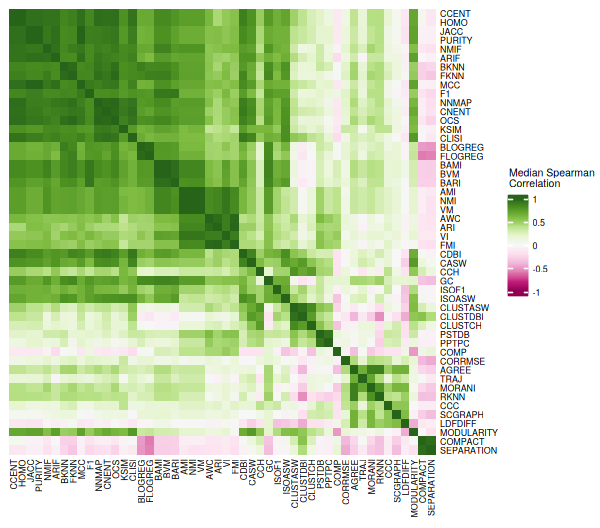

In [42]:
options(repr.plot.width=5, repr.plot.height=4.4)
# png("../publication_figures/bioconservation_corr_multiome_fixed.png", width = 5, height = 4.4, units = "in", res = 300, type = "cairo")



Heatmap(
    mat, name = "Median Spearman\nCorrelation",
    col = col_fun,

    # Fix the order to match the first heatmap
    row_order    = row_ord_flat,
    column_order = col_ord_flat,

    # No clustering needed — order is pre-specified
    cluster_rows    = FALSE,
    cluster_columns = FALSE,

    column_dend_height = unit(4, "cm"),
    row_dend_width     = unit(4, "cm"),

    # Row/column label font
    row_names_gp    = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5),

    # Legend font
    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp  = gpar(fontsize = 6)
    )
)
# dev.off()

In [45]:
options(repr.plot.width=4.1, repr.plot.height=5)
svglite("../publication_figures/bioconservation_corr_multiome_ward.svg", width = 4.1, height = 5)

my_block_cols = brewer.pal(11, "Set3")
grouping_map <- c(
    'FMI' = 2, 'AWC' = 2, 'ARI' = 2, 'VI' = 2, 'NMI' = 2, 'AMI' = 2, 'VM' = 2, 
    'BARI' = 2, 'BAMI' = 2, 'BVM' = 2, 
    'ISOASW' = 3, 'GC' = 3, 'ISOF1' = 3, 
    'CASW' = 4, 'CDBI' = 4, 'CCH' = 4, 'BLOGREG' = 1, 'FLOGREG' = 1, 'CLISI' = 0, 
    'FKNN' = 0, 'KSIM' = 0, 'OCS' = 0, 'NNMAP' = 0, 'CNENT' = 0, 'BKNN' = 0, 
    'F1' = 0, 'MCC' = 0, 'JACC' =0, 'PURITY' = 0, 'CCENT' = 0, 'HOMO' = 0, 'ARIF' = 0, 'NMIF' = 0, 
    'CLUSTCH' = 6, 'CLUSTASW' = 6, 'CLUSTDBI' = 6, 'COMP' = 5, 'PPTPC' = 5, 'PSTDB' = 5, 
    'LDFDIFF' = 7, 'AGREE' = 7, 'MORANI' = 7, 'RKNN' = 7, 'CCC' = 7, 'SCGRAPH' = 7, 'CORRMSE' = 7, 'TRAJ' = 7, 
    'MODULARITY' = 8, 'COMPACT' = 8, 'SEPARATION' = 8
)
col_groups <- unname(grouping_map[colnames(mat)])
ann_colors = brewer.pal(9, "Set3")
names(ann_colors) = as.character(0:8)

lgd = Legend(
    title = "Metric Category",
    type = "grid",
    labels = c(
        'Clusters-as-predictions\n& kNN',
        'Logistic regression',
        'Cluster-label similarity',
        'Isolated labels & GC',
        'Cell types as clusters',
        'Joint bioconservation\n& batch correction',
        'Cluster quality 1',
        'Fine-grained biology',
        'Cluster quality 2'
    ),
    legend_gp = gpar(fill = c(
        my_block_cols[1],  # 0
        my_block_cols[2],  # 1
        my_block_cols[3],  # 2
        my_block_cols[4],  # 3
        my_block_cols[5],  # 4
        my_block_cols[7],  # 5
        my_block_cols[6],  # 6
        my_block_cols[8],  # 7
        my_block_cols[9]   # 8
    )),
    title_gp = gpar(fontsize = 6),
    labels_gp = gpar(fontsize = 5),
    grid_height = unit(2, "mm"),
    grid_width = unit(2, "mm"),
    ncol=3
)
ht <- Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(.2, "in"),
    row_dend_width = unit(1, "cm"),
    row_names_gp    = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5),
    row_dend_gp    = gpar(lwd = 0.4),
    column_dend_gp = gpar(lwd = 0.4),
    show_row_dend = FALSE,
    row_title = NULL,

    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize =6),
        legend_height = unit(3, "mm"),
        legend_width = unit(2, "cm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm"),
        direction = "horizontal"
    ),
    bottom_annotation = HeatmapAnnotation(
        group = anno_simple(
            col_groups, height = unit(2, "mm"),
            col = ann_colors, border=F
#             annotation_border_gp = gpar(lwd = 0.5)
        ),
        show_legend = FALSE,
        show_annotation_name = FALSE,
        border = F
    )
)

draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd),
    merge_legend = TRUE,
    heatmap_legend_side = "bottom",
    annotation_legend_side = "bottom"
)
dev.off()

pdf 
  2

In [46]:
df <- read.csv('../results/spreadsheets/multiome_batch_corr.csv', row.names = 1)
mat <- as.matrix(df)

rownames(mat) <- toupper(rownames(mat))
colnames(mat) <- toupper(colnames(mat))


mat <- mat[rownames(mat) != "GCD", ]
mat <- mat[, colnames(mat) != "GCD"]

In [47]:
row_ord_flat <- unlist(row_ord_batch)
col_ord_flat <- unlist(col_ord_batch)

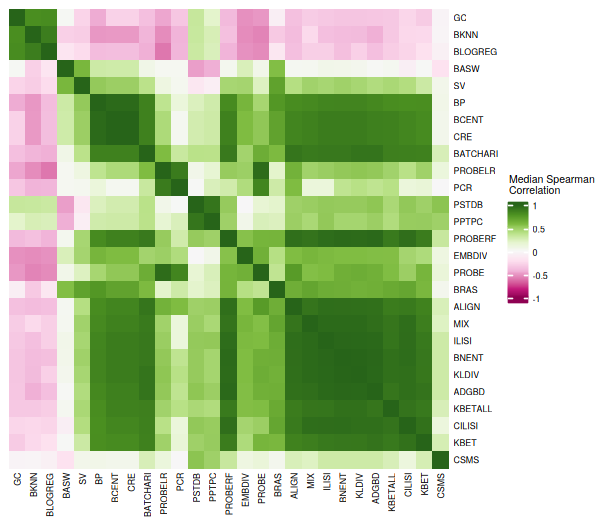

In [48]:
options(repr.plot.width=5, repr.plot.height=4.4)
# png("../publication_figures/batch_corr_multiome_fixed.png", width = 5, height = 4.4, units = "in", res = 300, type = "cairo")
Heatmap(
    mat, name = "Median Spearman\nCorrelation",
    col = col_fun,

    # Fix the order to match the first heatmap
    row_order    = row_ord_flat,
    column_order = col_ord_flat,

    # No clustering needed — order is pre-specified
    cluster_rows    = FALSE,
    cluster_columns = FALSE,

    column_dend_height = unit(4, "cm"),
    row_dend_width     = unit(4, "cm"),

    # Row/column label font
    row_names_gp    = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5),

    # Legend font
    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp  = gpar(fontsize = 6)
    )
)
# dev.off()

In [53]:
options(repr.plot.width=2.7, repr.plot.height=3.7)

svglite("../publication_figures/batch_corr_multiome_ward.svg", width = 2.7, height = 3.7)
my_block_cols = brewer.pal(9, "Set1")
grouping_map <- c(
    'MIX' = 0, "ALIGN" = 0, "ILISI" = 0, "BNENT" = 0, "KLDIV" = 0,
    "ADGBD" = 0, "KBETALL" = 0, "CILISI" = 0, "CSMS" = 0, "KBET" = 0,
    "BRAS" = 1, "EMBDIV" = 1, "PROBE" = 1, "PROBERF" = 1,
    "BATCHARI" = 2, "BP" = 2, "BCENT" = 2, "CRE" = 2,
    "PROBELR" = 3, "PCR" = 3,
    "PSTDB" = 4, "PPTPC" = 4, "BASW" = 5, "SV" = 5, "GC" = 6, "BKNN" = 6, "BLOGREG" = 6
)
# column_groups <- grouping_map[colnames(mat)]
# column_groups_factor <- factor(column_groups, levels = 0:6)
col_groups <- unname(grouping_map[colnames(mat)])
ann_colors = brewer.pal(9, "Set1")
names(ann_colors) = as.character(0:8)
ann_colors["2"] <- '#FFFFB3'   # Clustering gets yellow
ann_colors["1"] <- '#BEBADA'   # Unique metrics gets purple

lgd = Legend(
    title = "Metric Category",
    type = "grid",
    labels = c(
        'Primarily\nbioconservation',
        'BASW & SV',
        'Clustering metrics',
        'PCR & PROBELR',
        'Joint bioconservation\n& batch correction',
        'Unique metrics',
        'kNN'
    ),
    legend_gp = gpar(fill = c(
        my_block_cols[7],
        my_block_cols[6],
        my_block_cols[2],
        my_block_cols[4],
        my_block_cols[5],
        my_block_cols[3],
        my_block_cols[1]
    )),
    title_gp = gpar(fontsize = 6),
    labels_gp = gpar(fontsize = 5),
    grid_height = unit(2, "mm"),
    grid_width = unit(2, "mm"),
    ncol=2
)

ht = Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(.2, "in"),
    row_dend_width = unit(2, "cm"),
#     column_split = column_groups_factor, 
#     row_split = column_groups_factor,
    row_names_gp    = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5),
    row_dend_gp    = gpar(lwd = 0.4),
    column_dend_gp = gpar(lwd = 0.4),
    column_title = NULL,
    row_title = NULL,
    show_row_dend = FALSE,
        
    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize =6),
        legend_height = unit(3, "mm"),
        legend_width = unit(1.7, "cm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm"),
        direction = "horizontal"
        
    ),
    bottom_annotation = HeatmapAnnotation(
        group = anno_simple(
            col_groups, height = unit(2, "mm"),
            col = ann_colors, border=F),
        show_legend = FALSE,
        show_annotation_name = FALSE,
        border = F
    ),
)
ht_drawn <- draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd),
    merge_legend = TRUE,
    heatmap_legend_side = "bottom",
    annotation_legend_side = "bottom"
)
dev.off()

pdf 
  2

In [40]:
df <- read.csv('../results/spreadsheets/multiome_overall_corr_altered.csv', row.names = 1)
mat <- as.matrix(df)

# Capitalize all row names
rownames(mat) <- toupper(rownames(mat))

# Capitalize all column names
colnames(mat) <- toupper(colnames(mat))

In [41]:
# Define the sets with all names uppercased
BIO <- toupper(c('agree', 'ami', 'ari', 'arif', 'awc', 'bami', 'bari', 'bvm', 'casw', 
                 'ccc', 'cch', 'ccent', 'clustch', 'clisi', 'clustasw', 'clustdbi', 
                 'cnent', 'comp', 'compact', 'corrmse', 'cdbi', 'f1', 
                 'fknn', 'flogreg', 'fmi', 'homo', 'isoasw', 'isof1', 'jacc', 'ksim', 
                 'ldfdiff', 'mcc', 'modularity', 'morani', 'nmi', 'nmif', 'nnmap', 
                 'ocs', 'purity', 'rknn', 'scgraph', 'separation', 'traj', 'vi', 'vm'))

BATCH <- toupper(c('adgbd', 'align', 'basw', 'batchari', 'bcent', 'bknn', 'blogreg', 
                   'bnent', 'bp', 'bras', 'cre', 'cilisi', 'csms', 'gc', 
                   'ilisi', 'kbet', 'kbetall', 'kldiv', 'embdiv', 'mix','pcr', 'pptpc', 
                   'probe', 'proberf', 'probelr', 'pstdb', 'sv'))

BOTH <- toupper(c('pptpc', 'pstdb', 'blogreg', 'bknn', 'gc'))

# Combine into a unique set of all metric names
ALL_METRICS <- sort(unique(c(BIO, BATCH)))

# Create the mapping vector
# Initialize with NA
type_map <- setNames(rep(NA, length(ALL_METRICS)), ALL_METRICS)

# Assign groups (Uppercase labels: "BIO", "BATCH", "BOTH")
type_map[names(type_map) %in% BIO]   <- "Bioconservation metrics"
type_map[names(type_map) %in% BATCH] <- "Batch correction metrics"
type_map[names(type_map) %in% BOTH]  <- "Joint metrics"

# Finalize as a clean named character vector
type_map <- setNames(as.character(type_map), ALL_METRICS)

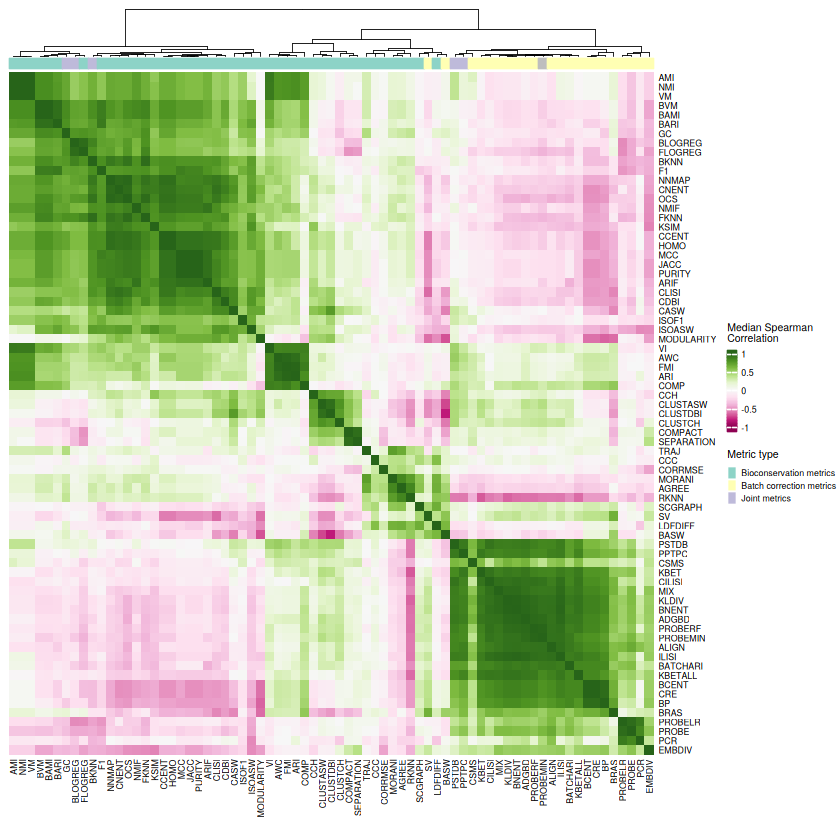

In [42]:
options(repr.plot.width=7, repr.plot.height=6.9)

# png("../publication_figures/overall_corr_multiome.png", width = 6.5, height = 6.4, units = "in", res = 300)

type_groups <- unname(type_map[colnames(mat)])
type_colors = brewer.pal(3, "Set3")
names(type_colors) = c("Bioconservation metrics", "Batch correction metrics", "Joint metrics")

lgd2 = Legend(
    title = "Metric type",
    at = names(type_colors),
    legend_gp = gpar(fill = my_block_cols[1:3]),
    title_gp = gpar(fontsize = 6),
    labels_gp = gpar(fontsize = 5),
    grid_height = unit(2, "mm"),
    grid_width = unit(2, "mm"),
)


ht = Heatmap(
    mat, name = "Median Spearman\nCorrelation",  
    clustering_method_rows = "ward.D2",  
    clustering_method_columns = "ward.D2",
    col = col_fun,
    column_dend_height = unit(1, "cm"),
    row_dend_width = unit(2, "cm"),
    column_dend_gp = gpar(lwd = 0.5),
    
    column_title = NULL,
    row_title = NULL,
    show_row_dend = FALSE,

    top_annotation = HeatmapAnnotation(
        group = anno_simple(
            type_groups, height = unit(2, "mm"),
            col = type_colors, border=F),
        show_legend = FALSE,
        show_annotation_name = FALSE,
        border = F
    ),
    heatmap_legend_param = list(
        labels_gp = gpar(fontsize = 5),
        title_gp = gpar(fontsize =6),
        legend_height = unit(1.7, "cm"),
        legend_width = unit(2, "mm"),
        grid_height = unit(2, "mm"),
        grid_width = unit(2, "mm")
    ),
    row_names_gp = gpar(fontsize = 5),
    column_names_gp = gpar(fontsize = 5)
)
draw(
    ht,
    ht_gap = unit(7, "mm"),
    annotation_legend_list = list(lgd2),
    merge_legend = TRUE,
    heatmap_legend_side = "right",
    annotation_legend_side = "right"
)
# dev.off()